# Datamol inspection → an honest D2 QSAR pilot
Adapted from Pat Walters’ [Datamol workflow](https://github.com/PatWalters/practical_cheminformatics_tutorials/blob/370dc66428819e06a2c87a859fab122b77b22f5b/datamol/datamol_1.ipynb): data → molecules → descriptors → property flags → clusters → visual inspection. Here it leads into the **actual frozen 80-compound model**, not a new hERG dataset.

**Result to reproduce:** Ridge RMSE **0.491 pKi**, versus training-mean **0.497**; both R² values are negative. No useful predictive skill is established. Datamol adds an inspection layer, not different training chemistry, labels, descriptors or a tuned split.

Use a fresh **Python 3.12 CPU** runtime. Setup downloads a commit-pinned, hash-checked public snapshot and installs official PyPI dependencies. It does not access Drive, run PubChemSR.exe, change a public site or publish results. Setup may upgrade or downgrade packages in this fresh runtime and may require a kernel restart. **Local execution is tested; actual Google Colab execution is not claimed.**


## 0. Set up once
The setup is separate from the scientific workflow. Original files remain read-only inputs; new outputs go to a separate run folder. Expand the cell to inspect the download/hash checks and exact package pins. A source dependency build may run during installation. No spreadsheet exporter is called.

In [1]:
#@title Setup: pinned source, package versions and integrity checks
from pathlib import Path, PurePosixPath
import hashlib, json, os, sys, subprocess, tempfile, uuid, urllib.request
import importlib.metadata as metadata
COMMIT='6d07e2ab78b54cc6aeb44523101a4672aa159705'
SOURCE_BASE_URL=f'https://raw.githubusercontent.com/DhruvMenon2003/drug-hansch-space/{COMMIT}/notebooks/qsar/chembl3855278/'
MANIFEST_SHA='cfb8b096f3c00c2be092993bbbfd90f1a15d8cbdcda6fb3f910dc508360f2cf9'

def digest(data): return hashlib.sha256(data).hexdigest()
def safe_name(name):
    p=PurePosixPath(name)
    if p.is_absolute() or '..' in p.parts or '\\' in name or not p.parts:
        raise ValueError('Unsafe manifest path')
    return p

def download(relative):
    safe_name(relative)
    with urllib.request.urlopen(SOURCE_BASE_URL+relative,timeout=60) as response:
        return response.read()

def fetch_bundle(base, fetch=download):
    """Fetch exactly the pinned, hash-verified package, never the EXE/site/repo tree."""
    base=Path(base).absolute()
    if base.resolve()!=base: raise ValueError('Symlinked base/ancestor rejected')
    base.mkdir(exist_ok=False)  # New private directory; never reuse caller-controlled contents.
    source=base/'frozen_source'; source.mkdir()
    raw=fetch('FINAL_MANIFEST.json')
    if digest(raw)!=MANIFEST_SHA: raise ValueError('Unexpected immutable-source manifest')
    manifest=json.loads(raw)
    if len(manifest)!=45 or not {'pilot.py','input_hashes.json','frozen/eligible_compounds.csv'}.issubset(manifest):
        raise ValueError('Unexpected package inventory')
    for name,expected in manifest.items():
        target=source/safe_name(name)
        if target.exists():
            if digest(target.read_bytes())!=expected: raise ValueError(f'Existing file changed: {name}; choose a fresh base directory')
            continue
        data=fetch(name)
        if digest(data)!=expected: raise ValueError(f'Download hash mismatch: {name}')
        target.parent.mkdir(parents=True,exist_ok=True); target.write_bytes(data)
    (source/'FINAL_MANIFEST.json').write_bytes(raw)
    return source

def verify_source(source):
    source=Path(source).absolute()
    if source.resolve()!=source: raise ValueError('Symlinked source/ancestor rejected')
    for path in source.rglob('*'):
        if path.is_symlink(): raise ValueError('Symlinks forbidden in frozen source')
    raw=(source/'FINAL_MANIFEST.json').read_bytes()
    if digest(raw)!=MANIFEST_SHA: raise ValueError('Manifest changed')
    for name,expected in json.loads(raw).items():
        if digest((source/safe_name(name)).read_bytes())!=expected: raise ValueError(f'Frozen source changed: {name}')


PINNED_REQUIREMENTS = 'aiobotocore==3.9.2\naiohappyeyeballs==2.7.1\naiohttp==3.14.5\naioitertools==0.13.0\naiosignal==1.4.0\nanyio==4.15.1\nargon2-cffi==25.1.0\nargon2-cffi-bindings==26.1.0\narrow==1.4.0\nasttokens==3.0.2\nasync-lru==2.4.0\nattrs==26.1.0\nbabel==2.18.0\nbackports.zstd==1.8.0\nbeautifulsoup4==4.15.0\nbleach==6.4.0\nbotocore==1.43.106\ncertifi==2026.10.19\ncffi==2.1.1\ncharset-normalizer==3.5.2\ncloudpickle==3.1.2\ncomm==0.2.3\ncontourpy==1.4.0\ncryptography==50.0.2\ncycler==0.12.1\ndatamol==0.13.0\ndebugpy==1.8.22\ndecorator==5.3.1\ndefusedxml==0.7.1\net_xmlfile==2.0.0\nexecuting==2.3.0\nfastjsonschema==2.22.2\nfonttools==4.67.0\nformulaic==1.2.2\nfqdn==1.6.0\nfrozenlist==1.8.0\nfsspec==2026.9.0\ngcsfs==2026.10.1\ngoogle-api-core==2.43.0\ngoogle-auth==2.62.0\ngoogle-auth-oauthlib==1.5.0\ngoogle-cloud-core==2.8.0\ngoogle-cloud-storage==3.17.1\ngoogle-cloud-storage-control==1.17.0\ngoogle-crc32c==1.9.0\ngoogle-resumable-media==2.11.0\ngoogleapis-common-protos==1.76.0\ngrpc-google-iam-v1==0.14.6\ngrpcio==1.84.1\ngrpcio-status==1.84.1\nh11==0.16.0\nhttpcore==1.0.9\nhttpx==0.28.1\nidna==3.20\ninterface_meta==2.0.1\nipykernel==7.4.0\nipython==9.17.1\nipython_pygments_lexers==1.1.1\nipywidgets==8.1.9\nisoduration==20.11.0\njedi==0.20.1\nJinja2==3.1.6\njmespath==1.1.0\njoblib==1.6.0\njson5==0.17.3\njsonpointer==3.4\njsonschema==4.26.0\njsonschema-specifications==2025.9.1\njupyter-events==0.12.1\njupyter-lsp==2.3.1\njupyter_builder==1.2.3\njupyter_client==8.10.0\njupyter_core==5.9.1\njupyter_server==2.21.1\njupyter_server_terminals==0.5.4\njupyterlab==4.6.4\njupyterlab_pygments==0.3.0\njupyterlab_server==2.28.1\njupyterlab_widgets==3.0.17\nkiwisolver==1.5.1\nlark==1.3.1\nloguru==0.7.3\nMarkupSafe==3.0.4\nmatplotlib==3.11.2\nmatplotlib-inline==0.2.2\nmistune==3.4.0\nmultidict==6.9.1\nnarwhals==2.27.1\nnbclient==0.11.0\nnbconvert==7.17.2\nnbformat==5.11.1\nnest-asyncio2==1.7.4\nnetworkx==3.7\nnglview==4.0.1\nnotebook==7.6.3\nnotebook_shim==0.2.4\nnumpy==2.5.4\noauthlib==4.0.0\nopenpyxl==3.1.5\nopentelemetry-api==1.45.1\npackaging==26.3\npandas==3.1.0\npandocfilters==1.5.1\nparso==0.8.7\npatsy==1.0.3\npexpect==4.9.0\npillow==13.0.0\nplatformdirs==4.13.5\nprometheus_client==0.26.0\nprompt_toolkit==3.0.53\npropcache==0.5.4\nproto-plus==1.29.0\nprotobuf==7.36.2\npsutil==7.2.2\nptyprocess==0.7.0\npure_eval==0.2.4\npy3Dmol==2.5.5\npyarrow==26.0.0\npyasn1==0.6.4\npyasn1_modules==0.4.2\npycparser==3.12\nPygments==2.21.0\npyparsing==3.3.3\npystow==0.10.3\npython-dateutil==2.9.0.post0\npython-json-logger==4.2.0\nPyYAML==6.0.3\npyzmq==27.2.0\nrdkit==2026.9.1\nreferencing==0.37.0\nrequests==2.34.2\nrequests-oauthlib==2.0.0\nrfc3339-validator==0.1.4\nrfc3986-validator==0.1.1\nrfc3987-syntax==1.1.0\nrpds-py==2026.9.1\ns3fs==2026.9.0\nscikit-learn==1.9.1\nscipy==1.18.1\nseaborn==0.13.2\nselfies==2.2.0\nSend2Trash==2.1.0\nsix==1.17.0\nsoupsieve==3.0.4\nstack-data==0.6.3\nstatsmodels==0.15.0\nterminado==0.18.1\nthreadpoolctl==3.7.0\ntinycss2==1.5.1\ntornado==6.6\ntqdm==4.70.1\ntraitlets==5.16.1\ntyping_extensions==4.16.0\ntzdata==2026.5\nuri-template==1.3.0\nurllib3==2.8.0\nuseful_rdkit_utils==2.0.1\nwcwidth==0.9.3\nwebcolors==25.10.0\nwebencodings==0.6.1\nwebsocket-client==1.9.2\nwidgetsnbextension==4.0.16\nwrapt==2.5.1\nxlsxwriter==3.3.0\nyarl==1.25.1\n'
if sys.version_info[:2] != (3, 12):
    raise RuntimeError('Use Python 3.12 for this tested stack; no silent version substitutions.')
IN_COLAB = 'google.colab' in sys.modules
INSTALL_DEPENDENCIES = IN_COLAB  # Local users: use the provided tested environment or explicitly opt in.
WORK_ROOT = Path(tempfile.gettempdir()) / ('qsar-datamol-' + uuid.uuid4().hex)
local_bundle = os.environ.get('QSAR_LOCAL_BUNDLE')  # Optional explicit offline fixture; never required on Colab.
if local_bundle:
    fixture = Path(local_bundle)
    SOURCE = fetch_bundle(WORK_ROOT, fetch=lambda name: (fixture / safe_name(name)).read_bytes())
else:
    SOURCE = fetch_bundle(WORK_ROOT)
verify_source(SOURCE)
OUTPUT = WORK_ROOT / 'run'
OUTPUT.mkdir()
for variable, name in [('MPLCONFIGDIR','matplotlib'), ('XDG_CACHE_HOME','cache'), ('PYSTOW_HOME','pystow')]:
    path = WORK_ROOT / name; path.mkdir()
    os.environ[variable] = str(path)

required = dict(line.split('==', 1) for line in PINNED_REQUIREMENTS.splitlines() if line.strip())
missing = []
for package, version in required.items():
    try:
        if metadata.version(package) != version:
            missing.append(package + '==' + version)
    except metadata.PackageNotFoundError:
        missing.append(package + '==' + version)
loaded_versions = {name: getattr(sys.modules.get(name), '__version__', None)
                   for name in ['numpy','pandas','rdkit','sklearn','scipy','matplotlib','datamol']}
if missing:
    if not INSTALL_DEPENDENCIES:
        raise RuntimeError('Missing/mismatched pinned packages. Use a fresh environment and install PINNED_REQUIREMENTS first: ' + ', '.join(missing[:10]))
    requirements_path = WORK_ROOT / 'requirements-datamol-tested.txt'
    requirements_path.write_text(PINNED_REQUIREMENTS)
    pip_env = {k:v for k,v in os.environ.items() if not k.upper().startswith('PIP_')}
    pip_env['PIP_CONFIG_FILE'] = os.devnull
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--index-url', 'https://pypi.org/simple',
                    '-r', str(requirements_path)], env=pip_env, check=True)
    # No --no-deps or alternate index. Official source builds are permitted when a wheel is absent.
    result = subprocess.run([sys.executable, '-m', 'pip', 'check'], env=pip_env,
                            text=True, capture_output=True)
    if result.returncode:
        raise RuntimeError('Runtime dependency conflict after setup; inspect it before continuing. No automatic cleanup/reset is performed.\n' + result.stdout + result.stderr)
from packaging.version import Version
module_to_dist = {'sklearn':'scikit-learn'}
conflicts = [name for name,version in loaded_versions.items() if version is not None
             and Version(str(version)) != Version(required[module_to_dist.get(name,name)])]
if conflicts:
    raise RuntimeError('Packages already loaded at different versions: ' + ', '.join(conflicts) +
                       '. Restart the kernel, then Run all. No automatic runtime reset is performed.')
for package, version in required.items():
    assert metadata.version(package) == version, package
verify_source(SOURCE)
print('Verified 45 frozen source files and the exact tested dependency set. No source/model changes.')


Verified 45 frozen source files and the exact tested dependency set. No source/model changes.


## 1. Read the measured-label cohort
One database-attributed human D2 binding assay, **CHEMBL3855278**, document **CHEMBL3853329**. Of 107 retrieved rows, 80 remain after missing-value and unresolved repeated-parent exclusions. All rows and decisions are retained in the frozen ledger.

The label is **original source-reported pKi**. Standardized Ki and the reverse conversion are checks on that same observation—not new experiments. Full source-table mapping is incomplete; the source-provenance note travels with the snapshot.


In [2]:
import json, sys
import numpy as np
import pandas as pd
import datamol as dm
from rdkit import Chem
from rdkit.Chem import Descriptors, rdFingerprintGenerator, Draw
from IPython.display import display, Image
import importlib.util
module_spec = importlib.util.spec_from_file_location('frozen_pilot', SOURCE / 'pilot.py')
pilot = importlib.util.module_from_spec(module_spec)
module_spec.loader.exec_module(pilot)
assert Path(pilot.__file__).resolve() == (SOURCE / 'pilot.py').resolve()
pilot.verify_frozen(SOURCE)
cohort = pd.read_csv(SOURCE / 'frozen/eligible_compounds.csv').reset_index(drop=True)
reference = pd.read_csv(SOURCE / 'results/model_dataset.csv')
assert len(cohort) == 80 and cohort.molecule_chembl_id.is_unique
assert np.array_equal(cohort.pKi, cohort.original_value)
display(cohort[['molecule_chembl_id', 'activity_id', 'original_type', 'original_relation',
                'pKi', 'standard_Ki_nM', 'assay_chembl_id']].head())
print('80 compounds; original pKi retained. Datamol', dm.__version__)


80 compounds; original pKi retained. Datamol 0.13.0


,molecule_chembl_id,activity_id,original_type,original_relation,pKi,standard_Ki_nM,assay_chembl_id
0,CHEMBL85606,16670133,pKi,=,6.31,489.78,CHEMBL3855278
1,CHEMBL3901211,16670136,pKi,=,6.15,707.95,CHEMBL3855278
2,CHEMBL3983937,16670139,pKi,=,6.10,794.33,CHEMBL3855278
3,CHEMBL3944642,16670142,pKi,=,6.20,630.96,CHEMBL3855278
4,CHEMBL3953365,16670148,pKi,=,6.10,794.33,CHEMBL3855278


## 2. Convert units; preserve structure identity
pKi = −log₁₀(Ki in mol/L), so **Ki(nM) = 10⁽⁹⁻ᵖᴷⁱ⁾**. ChEMBL’s standardized value may differ through rounding. Datamol parses the existing curated parent SMILES; no new cleanup, neutralization, tautomerization or stereochemistry removal is performed.


In [3]:
inspection = cohort.copy()
inspection['derived_Ki_nM_datamol'] = dm.molar.log_to_molar(cohort.pKi.to_numpy(), 'nM')
assert np.allclose(inspection.derived_Ki_nM_datamol, 10**(9-cohort.pKi), rtol=1e-12)
assert (abs(inspection.derived_Ki_nM_datamol-cohort.standard_Ki_nM)
        <= cohort.conversion_tolerance_nM).all()
# Explicit SMILES-only input prevents accidental reuse of a pre-existing Mol column.
molecules = dm.from_df(cohort[['molecule_chembl_id', 'parent_smiles']].copy(),
                       smiles_column='parent_smiles', conserve_smiles=True, sanitize=True)
assert all(m is not None for m in molecules)
assert [Chem.MolToInchiKey(m) for m in molecules] == cohort.parent_inchikey.tolist()
identity_before = [Chem.MolToSmiles(m, isomericSmiles=True) for m in molecules]
print('80/80 full stereochemical identities and unit-conversion checks passed.')


80/80 full stereochemical identities and unit-conversion checks passed.


## 3. Batch descriptors with explicit definitions
Walters passes a function dictionary to Datamol’s batch calculator. We do the same, using the **original five RDKit functions** so the model cannot change silently. Datamol’s alias `mw` is exact mass, not average `MolWt`; its Lipinski donor/acceptor aliases are also not substituted here.

Largest ring size is an extra **inspection-only** descriptor. Stable molecule IDs—not an accidental DataFrame index—join calculated values to evidence.


In [4]:
def max_ring_size(mol):
    return max((len(ring) for ring in mol.GetRingInfo().AtomRings()), default=0)

property_functions = {name: getattr(Descriptors, name) for name in pilot.FEATURES}
property_functions['max_ring_size_inspection'] = max_ring_size
properties = dm.descriptors.batch_compute_many_descriptors(
    molecules, properties_fn=property_functions, add_properties=False, n_jobs=1, progress=False)
assert len(properties) == len(cohort)
properties.insert(0, 'molecule_chembl_id', cohort.molecule_chembl_id.to_numpy())
inspection = inspection.merge(properties, on='molecule_chembl_id', validate='one_to_one', sort=False)
check = inspection[['molecule_chembl_id'] + pilot.FEATURES].merge(
    reference[['molecule_chembl_id'] + pilot.FEATURES], on='molecule_chembl_id',
    validate='one_to_one', suffixes=('_dm', '_frozen'))
for feature in pilot.FEATURES:
    assert np.allclose(check[feature+'_dm'], check[feature+'_frozen'], rtol=0, atol=1e-12)
display(inspection[['molecule_chembl_id'] + list(property_functions)].head())
print('All five Datamol-batched features match the frozen model features.')


All five Datamol-batched features match the frozen model features.


,molecule_chembl_id,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,max_ring_size_inspection
0,CHEMBL85606,438.575,4.84348,69.02,1,4,6
1,CHEMBL3901211,409.559,4.14032,59.98,0,6,6
2,CHEMBL3983937,409.559,4.14032,59.98,0,6,6
3,CHEMBL3944642,477.556,5.15912,59.98,0,6,6
4,CHEMBL3953365,463.529,4.76902,59.98,0,6,6


## 4. Property flags, not a new filter
The tutorial’s Rule-of-Five pattern is useful for inspection. Here it only annotates average molecular weight ≤500, calculated LogP ≤5, donors ≤5 and acceptors ≤10. It does **not** remove compounds, select features, imply safety, or establish applicability.


In [5]:
criteria = pd.DataFrame({'MW': inspection.MolWt <= 500, 'LogP': inspection.MolLogP <= 5,
                         'HBD': inspection.NumHDonors <= 5, 'HBA': inspection.NumHAcceptors <= 10})
inspection['ro5_criteria_met'] = criteria.sum(axis=1)
inspection['ro5_all_four'] = criteria.all(axis=1)
assert len(inspection) == 80
display(inspection.ro5_criteria_met.value_counts().sort_index().rename('Compound count'))


ro5_criteria_met
2     9
3    44
4    27
Name: Compound count, dtype: int64

## 5. Cluster for exploration—not validation
Datamol’s Butina clusters use explicit Morgan fingerprints: **radius 2, 2048 bits, no chirality**, with **distance cutoff 0.20** (1−Tanimoto; not similarity 0.20). Stereochemical source identities remain intact. Clusters can span train and holdout; they never replace the frozen scaffold split or choose a model.

Representatives are the first returned member of each cluster, not the most active molecule. Alignment changes depiction coordinates on **copies only**. Static molecule grids avoid the tutorial’s noted Colab widget-rendering issue.


33 exploratory clusters; first 12 representatives shown.


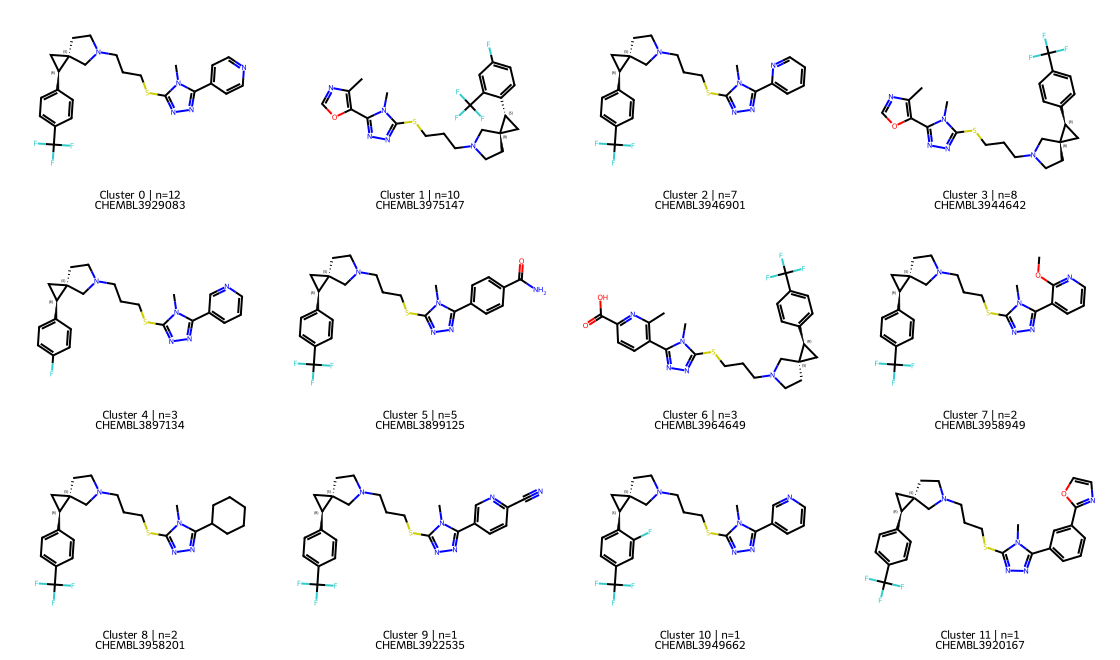

In [6]:
fingerprinter = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, includeChirality=False)
clusters, _ = dm.cluster_mols(molecules, cutoff=0.20,
                               feature_fn=fingerprinter.GetFingerprint, n_jobs=1)
cluster_ids = np.full(len(cohort), -1, dtype=int)
for cluster_id, members in enumerate(clusters):
    cluster_ids[list(members)] = cluster_id
assert (cluster_ids >= 0).all() and sum(map(len, clusters)) == 80
cluster_table = pd.DataFrame({'molecule_chembl_id': cohort.molecule_chembl_id,
                              'inspection_cluster': cluster_ids})
inspection = inspection.merge(cluster_table, on='molecule_chembl_id', validate='one_to_one')
inspection = inspection.merge(reference[['molecule_chembl_id', 'split']],
                              on='molecule_chembl_id', validate='one_to_one')
representative_indices = [members[0] for members in clusters]
display_molecules = [Chem.Mol(m) for m in molecules]
for members in clusters:
    aligned_cluster = dm.align.auto_align_many([display_molecules[i] for i in members],
                                               partition_method='scaffold', copy=True)
    for index, mol in zip(members, aligned_cluster):
        display_molecules[index] = mol
aligned = [display_molecules[i] for i in representative_indices]
assert [Chem.MolToSmiles(m, isomericSmiles=True) for m in display_molecules] == identity_before
assert [Chem.MolToSmiles(m, isomericSmiles=True) for m in molecules] == identity_before
legends = [f'Cluster {i} | n={len(clusters[i])}\n{cohort.iloc[idx].molecule_chembl_id}'
           for i, idx in enumerate(representative_indices)]
grid = dm.to_image(aligned[:12], legends=legends[:12], n_cols=4, mol_size=(280,220),
                   use_svg=False, copy=True)
grid.save(OUTPUT / 'cluster_representatives.png')
display(grid)
print(f'{len(clusters)} exploratory clusters; first 12 representatives shown.')


### Inspect one cluster
Change `CLUSTER_ID` to inspect another cluster. This affects the display only; all 80 compounds and the fixed model stay unchanged.

,molecule_chembl_id,pKi,split,ro5_criteria_met
29,CHEMBL3896638,6.48,train,3
32,CHEMBL3956758,6.27,train,4
40,CHEMBL3950540,6.46,train,3
42,CHEMBL3941818,6.44,train,2
44,CHEMBL3947961,6.06,train,3
45,CHEMBL3929083,6.21,train,3
46,CHEMBL3956612,5.87,train,3
47,CHEMBL3938107,6.05,train,3
52,CHEMBL3984236,6.36,train,4
53,CHEMBL3958309,6.53,train,4


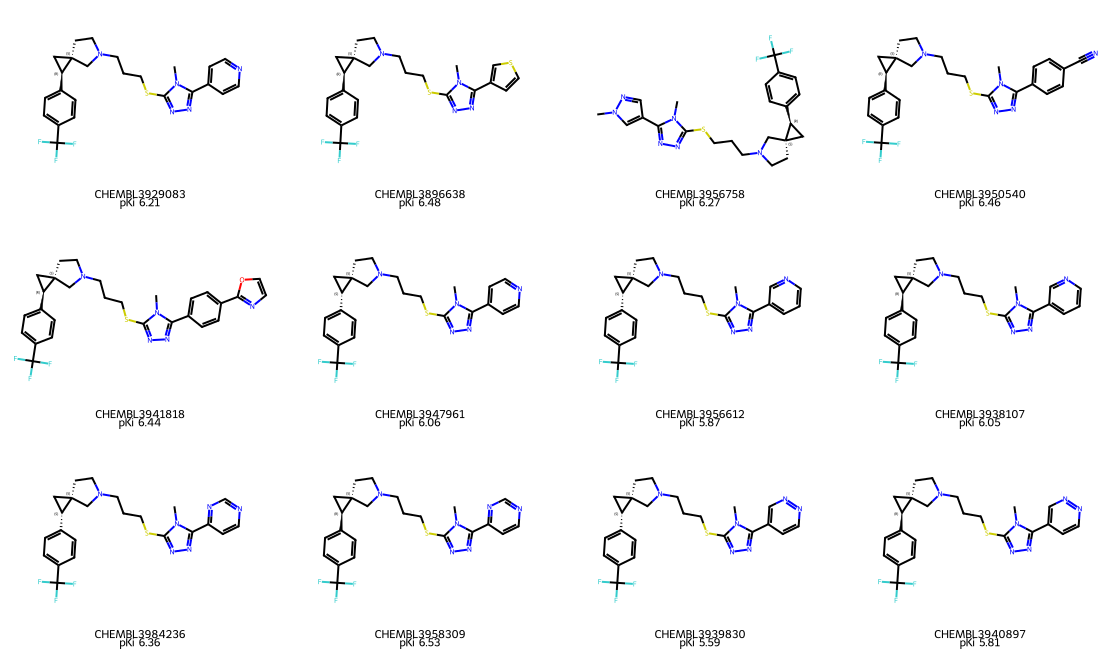

In [7]:
CLUSTER_ID = 0
assert 0 <= CLUSTER_ID < len(clusters)
indices = list(clusters[CLUSTER_ID])[:12]
display(inspection[inspection.inspection_cluster.eq(CLUSTER_ID)][
    ['molecule_chembl_id', 'pKi', 'split', 'ro5_criteria_met']])
cluster_grid = dm.to_image([Chem.Mol(display_molecules[i]) for i in indices],
    legends=[f'{cohort.iloc[i].molecule_chembl_id}\npKi {cohort.iloc[i].pKi:.2f}' for i in indices],
    n_cols=4, mol_size=(280,220), use_svg=False, copy=True)
cluster_grid.save(OUTPUT / 'selected_cluster.png')
display(cluster_grid)


## 6. Run the frozen QSAR recipe
The predeclared split remains **57 training / 23 holdout**, with no parent, connectivity or Murcko scaffold overlap. The 23 holdout rows cover only six scaffolds. Datamol clusters and Ro5 flags are **not** used for splitting or fitting.

Train-only `StandardScaler → Ridge(alpha=1)` and a training-mean baseline use the original five features. There is no tuning or all-data refit. The reviewed implementation is hash-verified `pilot.py`; it writes new results separately.


In [8]:
report = pilot.run(SOURCE, output=OUTPUT / 'model_results')
new_data = pd.read_csv(OUTPUT / 'model_results/model_dataset.csv')
new_predictions = pd.read_csv(OUTPUT / 'model_results/predictions.csv')
frozen_predictions = pd.read_csv(SOURCE / 'results/predictions.csv')
for column in ['molecule_chembl_id', 'split', 'parent_inchikey', 'connectivity_key', 'scaffold']:
    assert new_data[column].equals(reference[column]), column
for column in pilot.FEATURES + ['pKi']:
    assert np.allclose(new_data[column], reference[column], rtol=0, atol=1e-12), column
for column in ['predicted_pKi_ridge', 'predicted_pKi_train_mean']:
    assert np.allclose(new_predictions[column], frozen_predictions[column], rtol=0, atol=1e-10), column
frozen_report = json.loads((SOURCE / 'results/report.json').read_text())
for model, metrics in frozen_report['holdout_metrics'].items():
    for metric, value in metrics.items():
        assert abs(report['holdout_metrics'][model][metric] - value) < 1e-10
assert report['train_n'] == 57 and report['test_n'] == 23
display(pd.DataFrame(report['holdout_metrics']).T.round(4))


,test_n,MAE,RMSE,R2
training_mean,23.0,0.3757,0.4969,-0.0768
ridge_alpha_1,23.0,0.3699,0.4912,-0.0524


## 7. Read the errors honestly
Ridge barely improves on the training mean: MAE **0.370 vs 0.376**, RMSE **0.491 vs 0.497 pKi**. Both R² values are negative (**−0.052 vs −0.077**). Predictions remain close to the mean and miss the observed potency range. This is a reproducible weak pilot, not evidence of useful predictive validation.

A single assay/document and only six held-out scaffolds limit interpretation. Descriptor-range and nearest-training similarity annotations are descriptive warnings, not calibrated confidence. Nothing here improves or replaces the unrelated old 250-compound model.


Saved inspection CSV, molecule grids, model outputs and verification receipt in the run folder.


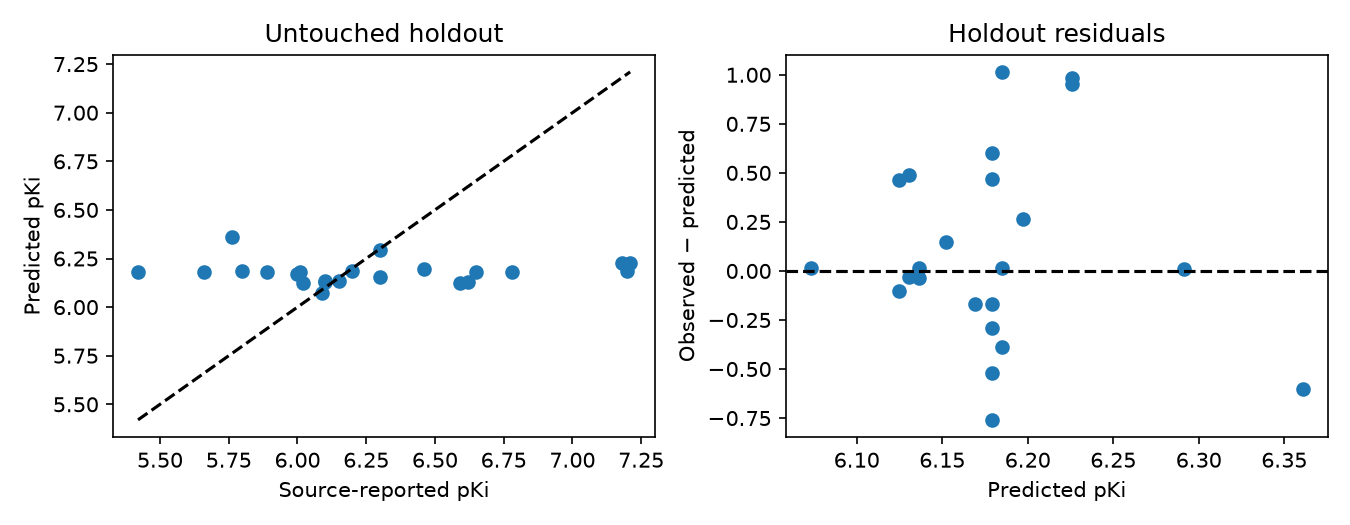

,molecule_chembl_id,pKi,predicted_pKi_ridge,residual_observed_minus_predicted,outside_training_descriptor_range,max_train_morgan_similarity
1,CHEMBL3901211,6.15,6.136685,0.013315,True,0.782609
2,CHEMBL3983937,6.10,6.136685,-0.036685,True,0.782609
3,CHEMBL3944642,6.20,6.185146,0.014854,False,0.969231
7,CHEMBL3975989,7.20,6.185146,1.014854,False,0.733333
8,CHEMBL3905196,5.80,6.185146,-0.385146,False,0.733333
9,CHEMBL3912029,6.10,6.130594,-0.030594,False,0.811594
10,CHEMBL3963783,6.62,6.130594,0.489406,False,0.811594
11,CHEMBL3945775,6.02,6.124502,-0.104502,False,0.697368
12,CHEMBL3926847,6.59,6.124502,0.465498,False,0.697368
13,CHEMBL3901587,6.01,6.179055,-0.169055,False,0.773333


In [9]:
display(Image(filename=str(OUTPUT / 'model_results/holdout.png')))
heldout = new_predictions[new_predictions.split.eq('test')]
display(heldout[['molecule_chembl_id', 'pKi', 'predicted_pKi_ridge',
    'residual_observed_minus_predicted', 'outside_training_descriptor_range',
    'max_train_morgan_similarity']].head(10))
inspection.to_csv(OUTPUT / 'datamol_inspection.csv', index=False)
verify_source(SOURCE)
receipt = {'source_commit': COMMIT, 'datamol_version': dm.__version__, 'cohort_n': 80,
    'five_features_match': True, 'full_identities_unchanged': True,
    'fixed_split_and_model_reproduced': True, 'exploratory_clusters': len(clusters),
    'no_ro5_filter_or_cluster_resplit': True, 'original_manifest_files_unchanged': True,
    'actual_google_colab_execution_verified': False}
(OUTPUT / 'integration_receipt.json').write_text(json.dumps(receipt, indent=2))
print('Saved inspection CSV, molecule grids, model outputs and verification receipt in the run folder.')


## Sources, scope and reuse
- Workflow adapted from **Patrick Walters, Practical Cheminformatics Tutorials**, pinned [Datamol notebook](https://github.com/PatWalters/practical_cheminformatics_tutorials/blob/370dc66428819e06a2c87a859fab122b77b22f5b/datamol/datamol_1.ipynb). Changes: fixed D2 cohort instead of hERG; corrected negative-log molar interpretation; explicit matching descriptors; flags rather than filtering; clustering/depiction only; unchanged QSAR validation.
- Datamol **0.13.0**, [official project](https://github.com/datamol-io/datamol), Apache-2.0. `useful_rdkit_utils` **2.0.1** remains the original model descriptor implementation.
- ChEMBL/EMBL-EBI source data and derived tables: [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/); source URLs, original fields and curation decisions remain in the frozen snapshot. Original study DOI **10.1021/acs.jmedchem.6b00972**, PMID **27564135**. Its D3 lead-series context does not turn these D2 labels into D3 measurements.
- The post-fit comparator check found no registered GSK598809 parent graph among all 107 source rows; no exclusion or model change followed. Exact “A” suffix/source figure and full table-to-record mapping were not independently resolved. This is a **database-attributed experimental-label** pilot, not independently reconstructed raw laboratory measurements.

The new inspection table and fitted JSON parameters can be downloaded from the runtime Files panel. No automatic upload, public sharing change or Excel export occurs.

### Adapted workflow license
MIT License

Copyright (c) 2022 Patrick Walters

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
